# 03 Classification models: Low, Mid or High spender?

**Goal of this notebook:** put each household into one of three expenditure groups (Low, Mid, High) and compare three classification models fairly.

- **Groups:** the three groups are expenditure *tertiles* (each holds about one third of households). The cut points are calculated on the **training set only**.
- **Models:** logistic regression, random forest, k-NN.
- **Two predictor settings:** Setting A (the four ANOVA variables) and Setting B (all usable variables, including income). Same settings and same 80/20 split as notebook 02.
- **Measures:** accuracy, and macro precision, macro recall and macro F1 (see Chapter 3.4 of the thesis). The confusion matrix shows which groups get mixed up.

How to use it: run one cell at a time (Shift+Enter) and read the output. Every section ends with a **Check yourself** question.

## Step 1. Import the tools
Each line says what the tool is used for.

In [1]:
import sys
sys.path.append("..")            # lets us import our own code from the src/ folder

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer          # applies different steps to different columns
from sklearn.pipeline import Pipeline                  # chains preprocessing + model into one object
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_val_score
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report)
from sklearn.base import clone                         # makes an unfitted copy of a model

from src.data import load_clean, make_split
from src.config import (FEATURES_A, FEATURES_B, NUMERIC, CATEGORICAL,
                        SEGMENT_LABELS, SEED, CV_FOLDS, FIG_DIR)

## Step 2. Load the data and use the SAME shared split
`make_split` gives the same 80/20 split as notebook 02 (seed 42). It also creates the `segment` column (Low / Mid / High).
The two cut points are taken from the **training** expenditures only, then applied to the test households.

In [2]:
df = load_clean()
train, test, cuts = make_split(df)

print("train rows:", len(train), "| test rows:", len(test))
print("cut points (GBP per week): Low/Mid =", round(cuts[0], 2), "| Mid/High =", round(cuts[1], 2))
print()
print("share of each group in the training set:")
print(train["segment"].value_counts(normalize=True).round(3))
print()
print("share of each group in the test set:")
print(test["segment"].value_counts(normalize=True).round(3))

train rows: 4115 | test rows: 1029
cut points (GBP per week): Low/Mid = 307.6 | Mid/High = 555.53

share of each group in the training set:
segment
Low     0.333
High    0.333
Mid     0.333
Name: proportion, dtype: float64

share of each group in the test set:
segment
Low     0.349
Mid     0.345
High    0.306
Name: proportion, dtype: float64


**Check yourself:** why do we calculate the cut points on the training set only and not on all 5,144 households? (Hint: the test households should stay completely unseen.)

**Answer:** We calculate the cut points using only the training households so the test households stay unseen until the final evaluation. If we used all 5,144 households to set the cut points, information from the test set would influence how the groups are defined. Keeping the test data separate makes the evaluation fairer.

## Step 3. Two small helpers
1. `make_preprocessor` one-hot encodes the category columns. Income is scaled (mean 0, spread 1). This matters for k-NN, which measures distances: without scaling, income in pounds would swamp the 0/1 columns.
2. `get_scores` calculates the four measures. **Macro** means: calculate the score for each of the three groups, then take the plain average, so every group counts equally.

In [3]:
def make_preprocessor(features):
    cat_cols = [c for c in features if c in CATEGORICAL]
    num_cols = [c for c in features if c in NUMERIC]
    return ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
        ("num", StandardScaler(), num_cols),
    ])


def get_scores(y_true, y_pred):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Macro precision": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "Macro recall": recall_score(y_true, y_pred, average="macro", zero_division=0),
        "Macro F1": f1_score(y_true, y_pred, average="macro", zero_division=0),
    }

**Check yourself:** with three equal groups, what accuracy would you get by guessing at random? Keep that number in mind when you read the results.

**Answer:** If we guessed randomly and each group were equally likely, the expected accuracy would be about **1/3, or 33.3%**. This is a simple reference point. The actual dummy model gets 30.6% accuracy because it always predicts the most common group in the training data, rather than guessing randomly.

## Step 4. A "no skill" baseline
A dummy model always predicts the most common group. Any real model should beat it clearly.

In [4]:
dummy = Pipeline([("prep", make_preprocessor(FEATURES_A)), ("model", DummyClassifier(strategy="most_frequent"))])
dummy.fit(train[FEATURES_A], train["segment"])
dummy_scores = get_scores(test["segment"], dummy.predict(test[FEATURES_A]))
print({k: round(v, 3) for k, v in dummy_scores.items()})

{'Accuracy': 0.306, 'Macro precision': 0.102, 'Macro recall': 0.333, 'Macro F1': 0.156}


**Check yourself:** why is the dummy's macro F1 much lower than its accuracy?

**Answer:** The dummy predicts only one group—the most common group—and never predicts the other two. That can give it some correct predictions and an accuracy of 30.6%, but its scores for the groups it never predicts are poor. Macro F1 averages the F1 score across all three groups equally, so it becomes much lower (0.156).

## Step 5. One function to run a model
For each model and predictor setting we do the same four things:
1. Build a pipeline (preprocessing + model).
2. Try a small grid of settings with 5-fold stratified cross-validation **on the training set only**, scored by macro F1. (Stratified means each fold keeps the same mix of Low / Mid / High.)
3. Report the cross-validated macro F1 (from the training set).
4. Score the best model once on the test set.

In [5]:
cv = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=SEED)
results = []        # one row per (setting, model)
best_models = {}    # keep the fitted models for the plots and the weighted check
best_params = {}


def run_model(setting, features, model_name, model, grid):
    pipe = Pipeline([("prep", make_preprocessor(features)), ("model", model)])
    X_train, y_train = train[features], train["segment"]

    search = GridSearchCV(pipe, grid, cv=cv, scoring="f1_macro", n_jobs=-1)
    search.fit(X_train, y_train)
    best = search.best_estimator_

    scores = get_scores(test["segment"], best.predict(test[features]))
    results.append({"Setting": setting, "Model": model_name,
                    "CV macro F1 (train)": search.best_score_, **{f"Test {k}": v for k, v in scores.items()},
                    "Best settings": str(search.best_params_)})
    best_models[(setting, model_name)] = best
    best_params[(setting, model_name)] = search.best_params_

**Check yourself:** why do we choose the settings by cross-validated macro F1 on the training set and not by looking at the test set?

**Answer:** Cross-validation lets us compare model settings using training data only. If we chose settings by checking the test set, we would be using the test data to make modelling decisions, so the final test score would no longer be a fully fair check on unseen data.

## Step 6. The three models
The grids are small on purpose: they are quick to run and easy to explain.
- Logistic regression: `C` controls how strongly the model is held back from fitting noise (smaller C = stronger hold-back).
- Random forest: `max_depth` and `min_samples_leaf` limit how detailed each tree can get.
- k-NN: `n_neighbors` is how many similar households vote on the group.

In [6]:
models = {
    "Logistic regression": (
        LogisticRegression(max_iter=2000),
        {"model__C": [0.1, 1, 10]},
    ),
    "Random forest": (
        RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=-1),
        {"model__max_depth": [5, 10], "model__min_samples_leaf": [5, 10]},
    ),
    "k-NN": (
        KNeighborsClassifier(),
        {"model__n_neighbors": [5, 15, 25, 50]},
    ),
}

### Setting A: the four ANOVA variables
Occupational class, tenure, number of adults, number of children.

In [7]:
for name, (model, grid) in models.items():
    run_model("A", FEATURES_A, name, clone(model), grid)
pd.DataFrame(results).round(3)

,Setting,Model,CV macro F1 (train),Test Accuracy,Test Macro precision,Test Macro recall,Test Macro F1,Best settings
0,A,Logistic regression,0.605,0.615,0.627,0.616,0.620,{'model__C': 1}
1,A,Random forest,0.602,0.603,0.612,0.606,0.607,"{'model__max_depth': 10, 'model__min_samples_l..."
2,A,k-NN,0.597,0.614,0.628,0.616,0.620,{'model__n_neighbors': 50}


### Setting B: all usable variables, including income
The random forest takes a few minutes here.

In [8]:
for name, (model, grid) in models.items():
    run_model("B", FEATURES_B, name, clone(model), grid)

## Step 7. Results table
The dummy baseline from Step 4 is added so everything is in one place.

In [9]:
results_df = pd.DataFrame(results)
dummy_row = {"Setting": "-", "Model": "Dummy (most common group)", "CV macro F1 (train)": np.nan,
             **{f"Test {k}": v for k, v in dummy_scores.items()}, "Best settings": "-"}
final_table = pd.concat([pd.DataFrame([dummy_row]), results_df], ignore_index=True)
final_table.round(3).to_csv("../reports/classification_results.csv", index=False)
final_table.round(3)

,Setting,Model,CV macro F1 (train),Test Accuracy,Test Macro precision,Test Macro recall,Test Macro F1,Best settings
0,-,Dummy (most common group),NaN,0.306,0.102,0.333,0.156,-
1,A,Logistic regression,0.605,0.615,0.627,0.616,0.620,{'model__C': 1}
2,A,Random forest,0.602,0.603,0.612,0.606,0.607,"{'model__max_depth': 10, 'model__min_samples_l..."
3,A,k-NN,0.597,0.614,0.628,0.616,0.620,{'model__n_neighbors': 50}
4,B,Logistic regression,0.657,0.673,0.671,0.674,0.672,{'model__C': 1}
5,B,Random forest,0.655,0.667,0.669,0.667,0.668,"{'model__max_depth': 10, 'model__min_samples_l..."
6,B,k-NN,0.638,0.651,0.646,0.653,0.649,{'model__n_neighbors': 25}


**Check yourself:** (1) Do the models beat the dummy and random guessing in Setting A? (2) How much does macro F1 change from Setting A to Setting B? (3) Is the best model clearly better than the others, or are they close? (4) Do cross-validated macro F1 and test macro F1 agree?

**Answer:** (1) Yes. In Setting A, the models reach test macro F1 scores of **0.620** for logistic regression, **0.607** for random forest and **0.605** for k-NN. These are above the dummy baseline of **0.156** and the rough random-guessing reference of **0.333**. (2) Setting B improves test macro F1 to **0.672** for logistic regression, **0.668** for random forest and **0.648** for k-NN—an improvement of about **0.04 to 0.05 points** compared with Setting A. (3) Logistic regression is the best model in both settings, but the differences from random forest are small. (4) Cross-validation and test macro F1 broadly agree: Setting B performs better than Setting A, and logistic regression ranks first in both settings.

## Step 8. Pictures of the results
First, test macro F1 for each model and setting. Then, for the best model of each setting (chosen by **cross-validated** macro F1, not by the test set), a confusion matrix: each row is the true group, and each cell shows what share of those households was predicted in each group.

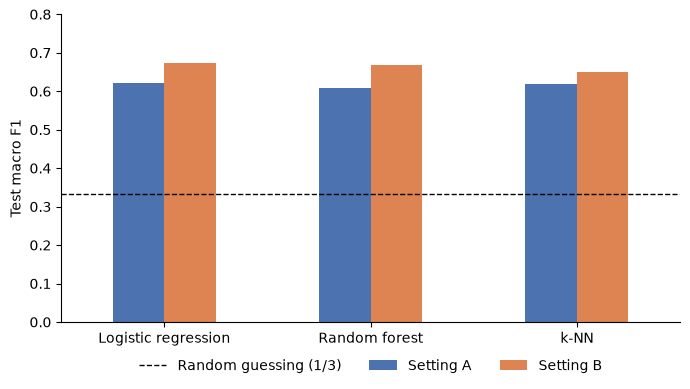

In [10]:
plot_df = results_df.pivot(index="Model", columns="Setting", values="Test Macro F1")
plot_df = plot_df.loc[["Logistic regression", "Random forest", "k-NN"]]
plot_df.columns = ["Setting " + c for c in plot_df.columns]

ax = plot_df.plot(kind="bar", figsize=(7, 4), color=["#4C72B0", "#DD8452"], rot=0)
ax.axhline(1 / 3, color="black", linestyle="--", linewidth=1, label="Random guessing (1/3)")
ax.set_ylabel("Test macro F1")
ax.set_xlabel("")
ax.set_ylim(0, 0.8)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=3, frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(FIG_DIR / "classification_test_f1.pdf")
plt.savefig(FIG_DIR / "classification_test_f1.png", dpi=300)
plt.show()

best by cross-validation: {'A': 'Logistic regression', 'B': 'Logistic regression'}


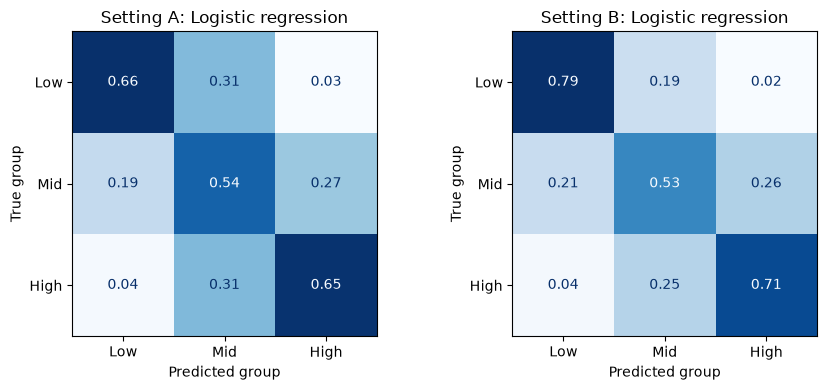

In [11]:
# best model per setting, chosen by cross-validated macro F1
best_name = {s: results_df[results_df["Setting"] == s].sort_values("CV macro F1 (train)").iloc[-1]["Model"]
             for s in ["A", "B"]}
print("best by cross-validation:", best_name)

fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, s in zip(axes, ["A", "B"]):
    features = FEATURES_A if s == "A" else FEATURES_B
    model = best_models[(s, best_name[s])]
    ConfusionMatrixDisplay.from_predictions(
        test["segment"], model.predict(test[features]), labels=SEGMENT_LABELS,
        normalize="true", values_format=".2f", cmap="Blues", colorbar=False, ax=ax)
    ax.set_title(f"Setting {s}: {best_name[s]}")
    ax.set_xlabel("Predicted group")
    ax.set_ylabel("True group")
plt.tight_layout()
plt.savefig(FIG_DIR / "classification_confusion.pdf")
plt.savefig(FIG_DIR / "classification_confusion.png", dpi=300)
plt.show()

**Check yourself:** (1) Which group is predicted best, and which is mixed up most? (2) When the model is wrong, is it usually wrong by one step (Low <-> Mid, Mid <-> High) or by two steps (Low <-> High)? Why does that make sense?

**Answer:** In both confusion matrices, the **Low** group is predicted best in Setting B (79% correctly classified), while **Mid** is the most difficult group (53% correctly classified). Most mistakes are between neighbouring groups: Low is often labelled Mid, and High is often labelled Mid. Low is rarely confused directly with High (about 2–4%). This makes sense because expenditure is continuous, so households close to a group cut point can have similar characteristics and be assigned to a neighbouring group.

## Step 9. Per-group scores for the best Setting B model
Precision, recall and F1 for each group separately. Macro F1 is the plain average of the three F1 values.

In [12]:
model = best_models[("B", best_name["B"])]
print(best_name["B"], "- Setting B")
print(classification_report(test["segment"], model.predict(test[FEATURES_B]),
                            labels=SEGMENT_LABELS, digits=3))

Logistic regression - Setting B
              precision    recall  f1-score   support

         Low      0.768     0.786     0.777       359
         Mid      0.558     0.530     0.543       355
        High      0.686     0.708     0.697       315

    accuracy                          0.673      1029
   macro avg      0.671     0.674     0.672      1029
weighted avg      0.671     0.673     0.672      1029



**Check yourself:** in your own words, what is the difference between precision and recall for the High group?

**Answer:** **Precision for High** means: of all households the model predicted as High, how many really were High? **Recall for High** means: of all households that really were High, how many did the model correctly identify? In Setting B, High precision is **0.686** and High recall is **0.708**. So the model finds about 71% of the actual High households, while about 69% of its High predictions are correct.

## Step 10. Sensitivity check: survey weights
The main results above are **unweighted**. As a check we score every best model with the survey weight `weightar`, and where the model allows it we also refit it with the weights.
k-NN has no option for sample weights, so for k-NN we only score with weights (the model itself is the unweighted one).

In [13]:
w_test = test["weightar"]
rows = []

for (setting, model_name), best in best_models.items():
    features = FEATURES_A if setting == "A" else FEATURES_B
    y_test = test["segment"]

    f1_unweighted_fit = f1_score(y_test, best.predict(test[features]), average="macro", sample_weight=w_test)

    if model_name == "k-NN":
        f1_weighted_fit = np.nan          # k-NN cannot use sample weights
    else:
        weighted = clone(best)
        weighted.fit(train[features], train["segment"], model__sample_weight=train["weightar"])
        f1_weighted_fit = f1_score(y_test, weighted.predict(test[features]), average="macro", sample_weight=w_test)

    rows.append({"Setting": setting, "Model": model_name,
                 "Weighted test macro F1 (unweighted fit)": f1_unweighted_fit,
                 "Weighted test macro F1 (weighted fit)": f1_weighted_fit})

sens = pd.DataFrame(rows)
sens.round(3).to_csv("../reports/classification_weighted_check.csv", index=False)
sens.round(3)

,Setting,Model,Weighted test macro F1 (unweighted fit),Weighted test macro F1 (weighted fit)
0,A,Logistic regression,0.628,0.633
1,A,Random forest,0.613,0.613
2,A,k-NN,0.623,NaN
3,B,Logistic regression,0.674,0.680
4,B,Random forest,0.671,0.668
5,B,k-NN,0.656,NaN


**Check yourself:** does the ranking of the models change when the weights are used?

**Answer:** No. The ranking stays the same in both settings: logistic regression performs best, random forest is second, and k-NN is third. With weighted scoring, Setting A macro F1 is 0.628 for logistic regression, 0.613 for random forest and 0.609 for k-NN. In Setting B, the weighted scores are 0.674, 0.671 and 0.656 respectively. The weighted-fit results tell a similar story, although k-NN cannot be refitted with sample weights in this notebook.

## Step 11. Summary

Write 4 to 6 sentences in your own words:
1. Do the models beat random guessing in Setting A?
2. How much does Setting B improve on Setting A?
3. Which model is best, and is the difference large or small?
4. Which groups get confused, and what does that tell you?
5. What does the weighted check say?

### Completed summary

The models perform better than the dummy baseline and the random-guessing reference in Setting A, although their scores are fairly close to one another. Adding income and the other available household variables in Setting B improves test macro F1 by around 0.04–0.05 points, with logistic regression reaching 0.672. Logistic regression is the best model in both settings, but its advantage over random forest is small. The models predict the Low and High groups more reliably than the Mid group, and most errors are between neighbouring expenditure groups. The survey-weight check does not change the model ranking: logistic regression remains first, random forest second and k-NN third.